In [61]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
roc_auc_score, confusion_matrix, classification_report,roc_curve)

import joblib

In [62]:
df = pd.read_csv("german_credit_data.csv")
df.head()

,status_account,month_duration,credit_history,purpose,credit_amount,status_savings,years_employment,payment_to_income_ratio,status_and_sex,secondary_obligor,...,collateral,age,other_installment_plans,housing,n_credits,job,n_guarantors,telephone,is_foreign_worker,target
0,< 0 DM,6,critical account/ other credits existing (not ...,radio/television,1169,unknown/ no savings account,>= 7 years,4,male : single,none,...,none,67,none,own,2,skilled employee/ official,1,"yes, registered under the customers name",yes,good
1,0 to < 200 DM,48,existing credits paid back duly till now,radio/television,5951,< 100 DM,1 to < 4 years,2,female : divorced/separated/married,none,...,none,22,none,own,1,skilled employee/ official,1,none,yes,bad
2,no checking account,12,critical account/ other credits existing (not ...,education,2096,< 100 DM,4 to < 7 years,2,male : single,none,...,none,49,none,own,1,unskilled - resident,2,none,yes,good
3,< 0 DM,42,existing credits paid back duly till now,furniture/equipment,7882,< 100 DM,4 to < 7 years,2,male : single,guarantor,...,car,45,none,for free,1,skilled employee/ official,2,none,yes,good
4,< 0 DM,24,delay in paying off in the past,car (new),4870,< 100 DM,1 to < 4 years,3,male : single,none,...,savings agreement/life insurance,53,none,for free,2,skilled employee/ official,2,none,yes,bad


In [63]:
df.columns

Index(['status_account', 'month_duration', 'credit_history', 'purpose',
       'credit_amount', 'status_savings', 'years_employment',
       'payment_to_income_ratio', 'status_and_sex', 'secondary_obligor',
       'residence_since', 'collateral', 'age', 'other_installment_plans',
       'housing', 'n_credits', 'job', 'n_guarantors', 'telephone',
       'is_foreign_worker', 'target'],
      dtype='object')

In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   status_account           1000 non-null   object
 1   month_duration           1000 non-null   int64 
 2   credit_history           1000 non-null   object
 3   purpose                  1000 non-null   object
 4   credit_amount            1000 non-null   int64 
 5   status_savings           1000 non-null   object
 6   years_employment         1000 non-null   object
 7   payment_to_income_ratio  1000 non-null   int64 
 8   status_and_sex           1000 non-null   object
 9   secondary_obligor        1000 non-null   object
 10  residence_since          1000 non-null   int64 
 11  collateral               1000 non-null   object
 12  age                      1000 non-null   int64 
 13  other_installment_plans  1000 non-null   object
 14  housing                  1000 non-null   

In [65]:
df.isnull().sum()

status_account             0
month_duration             0
credit_history             0
purpose                    0
credit_amount              0
status_savings             0
years_employment           0
payment_to_income_ratio    0
status_and_sex             0
secondary_obligor          0
residence_since            0
collateral                 0
age                        0
other_installment_plans    0
housing                    0
n_credits                  0
job                        0
n_guarantors               0
telephone                  0
is_foreign_worker          0
target                     0
dtype: int64

In [66]:
df.drop("age", axis=1, inplace=True, errors="ignore")

## FEATURE ENGINEERING

In [67]:
df["credit_per_month"] = (df["credit_amount"] / df["month_duration"])

In [68]:
df["credit_burden"] = (df["credit_amount"] *df["payment_to_income_ratio"])

In [69]:
df["duration_group"] = pd.cut(df["month_duration"],
    bins=[0, 12, 24, 48, np.inf],
    labels=["Short", "Medium", "Long", "Very_Long"])

In [70]:
df["duration_group"] = df["duration_group"].astype(str)

In [71]:
df.head()

,status_account,month_duration,credit_history,purpose,credit_amount,status_savings,years_employment,payment_to_income_ratio,status_and_sex,secondary_obligor,...,housing,n_credits,job,n_guarantors,telephone,is_foreign_worker,target,credit_per_month,credit_burden,duration_group
0,< 0 DM,6,critical account/ other credits existing (not ...,radio/television,1169,unknown/ no savings account,>= 7 years,4,male : single,none,...,own,2,skilled employee/ official,1,"yes, registered under the customers name",yes,good,194.833333,4676,Short
1,0 to < 200 DM,48,existing credits paid back duly till now,radio/television,5951,< 100 DM,1 to < 4 years,2,female : divorced/separated/married,none,...,own,1,skilled employee/ official,1,none,yes,bad,123.979167,11902,Long
2,no checking account,12,critical account/ other credits existing (not ...,education,2096,< 100 DM,4 to < 7 years,2,male : single,none,...,own,1,unskilled - resident,2,none,yes,good,174.666667,4192,Short
3,< 0 DM,42,existing credits paid back duly till now,furniture/equipment,7882,< 100 DM,4 to < 7 years,2,male : single,guarantor,...,for free,1,skilled employee/ official,2,none,yes,good,187.666667,15764,Long
4,< 0 DM,24,delay in paying off in the past,car (new),4870,< 100 DM,1 to < 4 years,3,male : single,none,...,for free,2,skilled employee/ official,2,none,yes,bad,202.916667,14610,Medium


In [72]:
df.isnull().sum()

status_account             0
month_duration             0
credit_history             0
purpose                    0
credit_amount              0
status_savings             0
years_employment           0
payment_to_income_ratio    0
status_and_sex             0
secondary_obligor          0
residence_since            0
collateral                 0
other_installment_plans    0
housing                    0
n_credits                  0
job                        0
n_guarantors               0
telephone                  0
is_foreign_worker          0
target                     0
credit_per_month           0
credit_burden              0
duration_group             0
dtype: int64

## TARGET PREPARATION

In [73]:
df["target"].unique()

array(['good', 'bad'], dtype=object)

In [74]:
df["target"].value_counts(dropna=False)

target
good    700
bad     300
Name: count, dtype: int64

In [75]:
df["target"] = df["target"].map(
    {"good": 0,
    "bad": 1
})

In [76]:
df["target"].value_counts(dropna=False)

target
0    700
1    300
Name: count, dtype: int64

## VISUALIZATIONS

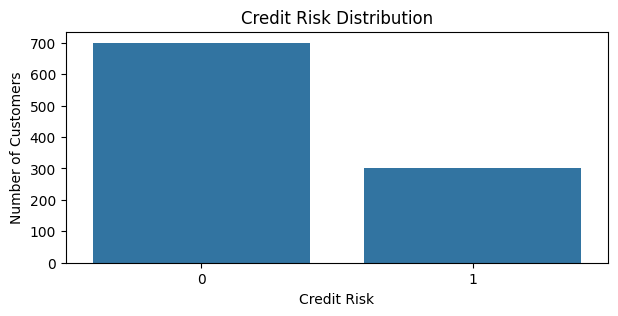

In [77]:
plt.figure(figsize=(7, 3))
sns.countplot(x="target", data=df)
plt.title("Credit Risk Distribution")
plt.xlabel("Credit Risk")
plt.ylabel("Number of Customers")
plt.show()

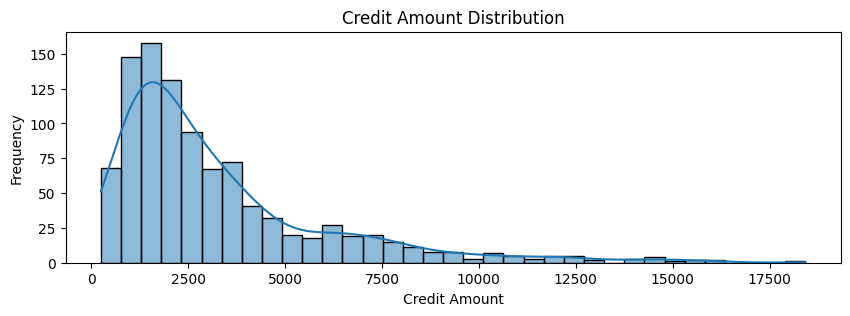

In [78]:
plt.figure(figsize=(10,3))
sns.histplot(data=df, x="credit_amount", kde=True)
plt.title("Credit Amount Distribution")
plt.xlabel("Credit Amount")
plt.ylabel("Frequency")
plt.show()

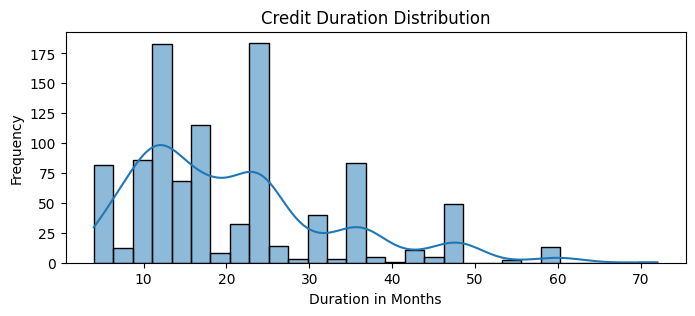

In [79]:
plt.figure(figsize=(8, 3))
sns.histplot(data=df, x="month_duration", kde=True)
plt.title("Credit Duration Distribution")
plt.xlabel("Duration in Months")
plt.ylabel("Frequency")
plt.show()

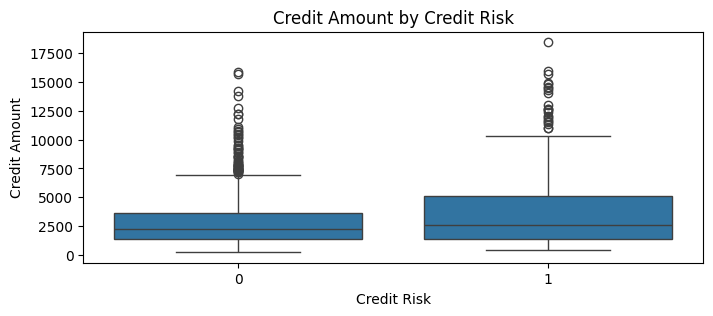

In [80]:
plt.figure(figsize=(8, 3))
sns.boxplot(data=df, x="target", y="credit_amount")
plt.title("Credit Amount by Credit Risk")
plt.xlabel("Credit Risk")
plt.ylabel("Credit Amount")
plt.show()

## PREPARE DATA FOR MODELS

In [81]:
X = df.drop("target", axis=1)
y = df["target"]

In [82]:
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns

In [83]:
categorical_features = X.select_dtypes(include=["object"]).columns

In [84]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)

In [85]:
preprocessor = ColumnTransformer(
    transformers=[("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)])

## Logistic Regression

In [86]:
logistic_model = Pipeline(steps=[("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))])

In [87]:
logistic_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [91]:
logistic_pred = logistic_model.predict(X_test)
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]

## Decision Tree

In [92]:
decision_tree_model = Pipeline(steps=[("preprocessor", preprocessor),
                ("classifier", DecisionTreeClassifier(max_depth=5, random_state=42))])

In [93]:
decision_tree_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [94]:
decision_tree_pred = decision_tree_model.predict(X_test)
decision_tree_prob = decision_tree_model.predict_proba(X_test)[:, 1]

## Random Forest

In [95]:
random_forest_model = Pipeline(steps=[("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier( n_estimators=200, max_depth=10, random_state=42))])

In [96]:
random_forest_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [97]:
random_forest_pred = random_forest_model.predict(X_test)
random_forest_prob = random_forest_model.predict_proba( X_test)[:, 1]

## MODEL EVALUATION

In [98]:
###Accuracy
logistic_accuracy = accuracy_score(y_test, logistic_pred)

decision_tree_accuracy = accuracy_score(y_test, decision_tree_pred)

random_forest_accuracy = accuracy_score(y_test, random_forest_pred)

In [99]:
###Precision
logistic_precision = precision_score(y_test, logistic_pred)

decision_tree_precision = precision_score(y_test, decision_tree_pred)

random_forest_precision = precision_score(y_test, random_forest_pred)

In [43]:
###Recall
logistic_recall = recall_score(y_test, logistic_pred)

decision_tree_recall = recall_score(y_test, decision_tree_pred)

random_forest_recall = recall_score(y_test, random_forest_pred)

In [44]:
###F1_score
logistic_f1 = f1_score(y_test, logistic_pred)

decision_tree_f1 = f1_score(y_test, decision_tree_pred)

random_forest_f1 = f1_score(y_test, random_forest_pred)

In [45]:
###Roc-Auc
logistic_roc_auc = roc_auc_score(y_test, logistic_prob)

decision_tree_roc_auc = roc_auc_score(y_test, decision_tree_prob)

random_forest_roc_auc = roc_auc_score(y_test, random_forest_prob)

In [46]:
##Final Model Comparison
results = pd.DataFrame({"Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    
    "Accuracy": [logistic_accuracy, decision_tree_accuracy, random_forest_accuracy],
    "Precision": [logistic_precision, decision_tree_precision, random_forest_precision],
    "Recall": [logistic_recall, decision_tree_recall, random_forest_recall],
    "F1-Score": [logistic_f1, decision_tree_f1, random_forest_f1],
    "ROC-AUC": [logistic_roc_auc, decision_tree_roc_auc, random_forest_roc_auc]})
results

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.785,0.642857,0.610169,0.626087,0.830508
1,Decision Tree,0.740,0.620690,0.305085,0.409091,0.775273
2,Random Forest,0.790,0.774194,0.406780,0.533333,0.831110


## VISUALIZATION OF MODEL RESULTS

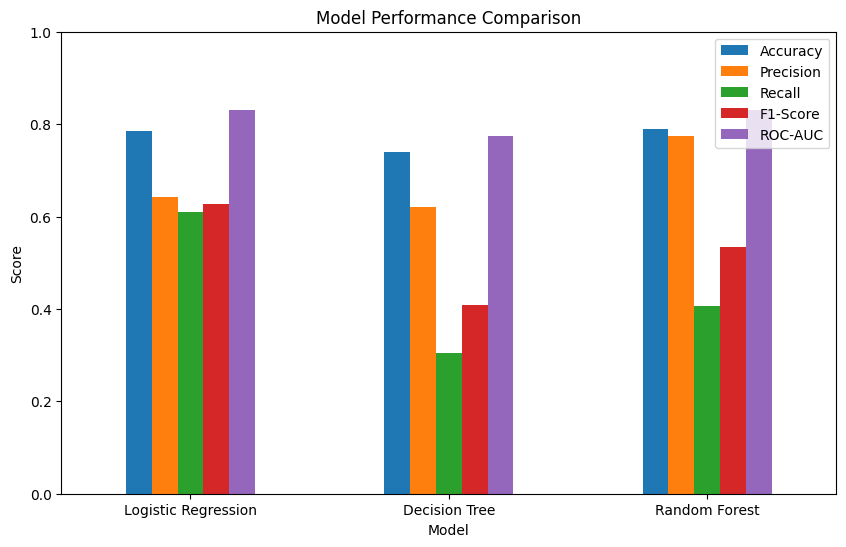

In [102]:
results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]].plot(kind="bar", figsize=(10, 6))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

In [48]:
##Roc Curve
logistic_fpr, logistic_tpr, _ = roc_curve(y_test, logistic_prob)

decision_tree_fpr, decision_tree_tpr, _ = roc_curve(y_test, decision_tree_prob)

random_forest_fpr, random_forest_tpr, _ = roc_curve(y_test, random_forest_prob)

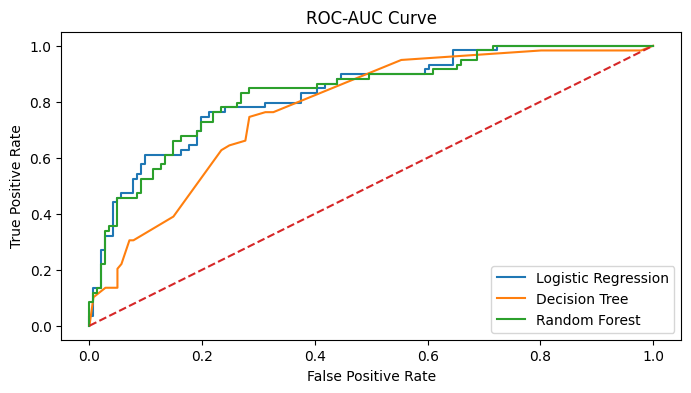

In [49]:
plt.figure(figsize=(8,4))
plt.plot(logistic_fpr, logistic_tpr, label="Logistic Regression")
plt.plot(decision_tree_fpr, decision_tree_tpr, label="Decision Tree")
plt.plot(random_forest_fpr, random_forest_tpr, label="Random Forest")
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curve")
plt.legend()
plt.show()

In [60]:
##Confusion Matrix for Random Forest
cm = confusion_matrix(y_test, random_forest_pred)

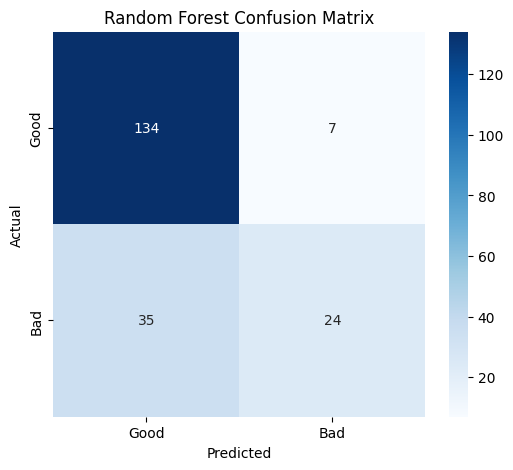

In [51]:
plt.figure(figsize=(6, 5))
sns.heatmap( cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Good", "Bad"], yticklabels=["Good", "Bad"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

## FEATURE IMPORTANCE

In [105]:
feature_names = (random_forest_model.named_steps["preprocessor"].get_feature_names_out())
importance_values = (random_forest_model.named_steps["classifier"].feature_importances_)
feature_importance = pd.DataFrame({"Feature": feature_names, "Importance": importance_values})
feature_importance = feature_importance.sort_values(by="Importance", ascending=False)

In [110]:
feature_importance.head(10)

,Feature,Importance
6,num__credit_per_month,0.084963
7,num__credit_burden,0.081611
1,num__credit_amount,0.080355
0,num__month_duration,0.058743
11,cat__status_account_no checking account,0.056720
9,cat__status_account_< 0 DM,0.044148
2,num__payment_to_income_ratio,0.024844
3,num__residence_since,0.024463
13,cat__credit_history_critical account/ other cr...,0.022266
18,cat__purpose_car (new),0.018377


## CLASSIFICATION REPORTS

In [111]:
classification_report(y_test, logistic_pred, target_names=["Good", "Bad"])

'              precision    recall  f1-score   support\n\n        Good       0.84      0.86      0.85       141\n         Bad       0.64      0.61      0.63        59\n\n    accuracy                           0.79       200\n   macro avg       0.74      0.73      0.74       200\nweighted avg       0.78      0.79      0.78       200\n'

In [112]:
classification_report(y_test, decision_tree_pred, target_names=["Good", "Bad"])

'              precision    recall  f1-score   support\n\n        Good       0.76      0.92      0.83       141\n         Bad       0.62      0.31      0.41        59\n\n    accuracy                           0.74       200\n   macro avg       0.69      0.61      0.62       200\nweighted avg       0.72      0.74      0.71       200\n'

In [113]:
classification_report(y_test, random_forest_pred, target_names=["Good", "Bad"])

'              precision    recall  f1-score   support\n\n        Good       0.79      0.95      0.86       141\n         Bad       0.77      0.41      0.53        59\n\n    accuracy                           0.79       200\n   macro avg       0.78      0.68      0.70       200\nweighted avg       0.79      0.79      0.77       200\n'

## SAVE MODEL

In [114]:
joblib.dump(random_forest_model, "credit_scoring_random_forest.pkl")

['credit_scoring_random_forest.pkl']

In [117]:
print("Credit_scoring_random_forest_model saved successfully")

Credit_scoring_random_forest_model saved successfully
